# Delivery-time prediction: walkthrough

Same pipeline as the scripts in `src/`, with the intermediate tables and charts shown. Run `run_all.sh` first so the data and models exist.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd
import matplotlib.pyplot as plt
from src.prepare import load_raw, build_features, feature_columns, TARGET

raw = load_raw('../data/cleaned_data.csv')
print(raw.shape)
raw.head(3)

(43862, 24)


,ID,Delivery_person_ID,courier_age,courier_rating,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,order_type,vehicle_type,multiple_deliveries,festival,city,time_taken_min,Time_To_Pick,Order_Year,Order_Month,Order_Day
0,0x4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,2022-03-19 11:30:00,...,Snack,motorcycle,0.0,No,Urban,24.0,15.0,2022.0,March,Saturday
1,0xb379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,2022-03-25 19:45:00,...,Snack,scooter,1.0,No,Metropolitian,33.0,5.0,2022.0,March,Friday
2,0x5d6d,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,2022-03-19 08:30:00,...,Drinks,motorcycle,1.0,No,Urban,26.0,15.0,2022.0,March,Saturday


## 1. Target

40,353 deliveries, 31 features


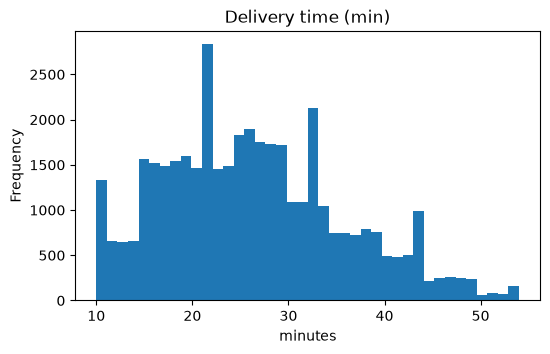

count    40353.0
mean        26.3
std          9.4
min         10.0
25%         19.0
50%         26.0
75%         32.0
max         54.0
Name: time_taken_min, dtype: float64

In [2]:
table = build_features(raw)
print(f'{len(table):,} deliveries, {len(feature_columns(table))} features')
ax = table[TARGET].plot.hist(bins=40, figsize=(6, 3.5), title='Delivery time (min)')
ax.set_xlabel('minutes'); plt.show()
table[TARGET].describe().round(1)

## 2. What the raw relationships look like

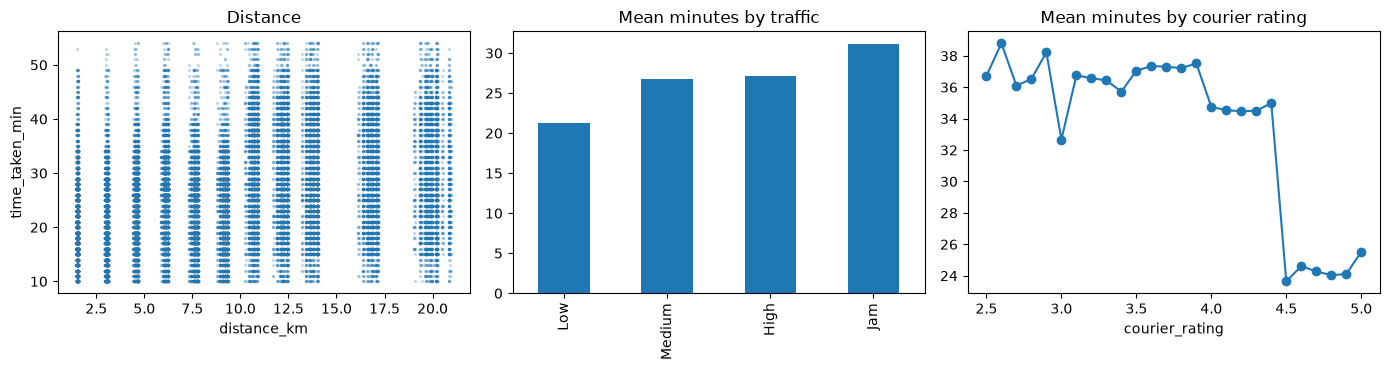

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
table.plot.scatter('distance_km', TARGET, s=2, alpha=0.2, ax=axes[0], title='Distance')
traffic_cols = [c for c in table.columns if c.startswith('traffic_')]
means = {c.replace('traffic_', ''): table.loc[table[c] == 1, TARGET].mean() for c in traffic_cols}
pd.Series(means).sort_values().plot.bar(ax=axes[1], title='Mean minutes by traffic')
table.groupby('courier_rating')[TARGET].mean().plot(ax=axes[2], marker='o', title='Mean minutes by courier rating')
plt.tight_layout(); plt.show()

## 3. Model results

Written by `src/model.py`, `src/explain.py` and `src/pca.py`.

In [4]:
m = json.load(open('../results/metrics.json'))
rows = {k: v for k, v in m['models'].items()}
rows[f"xgboost on {m['pca']['n_components_95pct']} PCs"] = m['pca']['xgboost_on_components']
pd.DataFrame(rows).T

,r2,mae,rmse
linear_regression,0.5997,4.727,5.934
random_forest,0.8354,3.071,3.805
xgboost,0.8380,3.048,3.776
xgboost on 22 PCs,0.7775,3.510,4.424


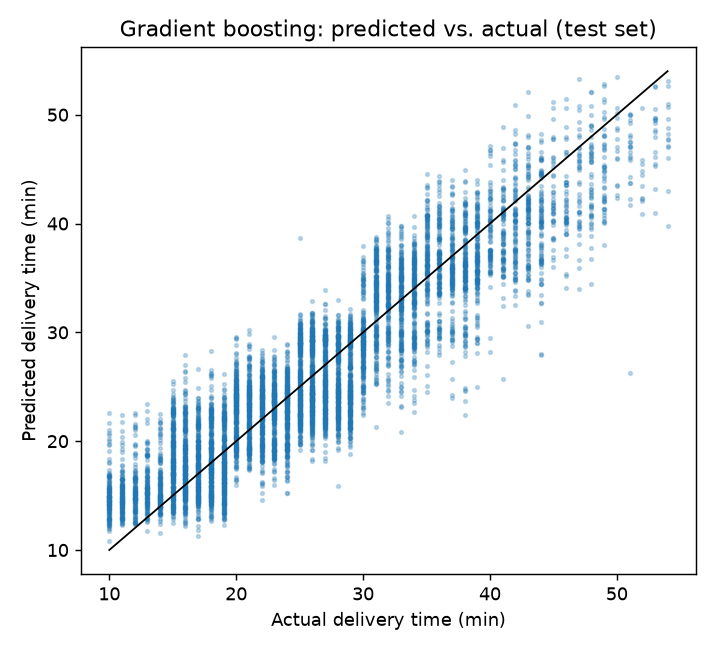

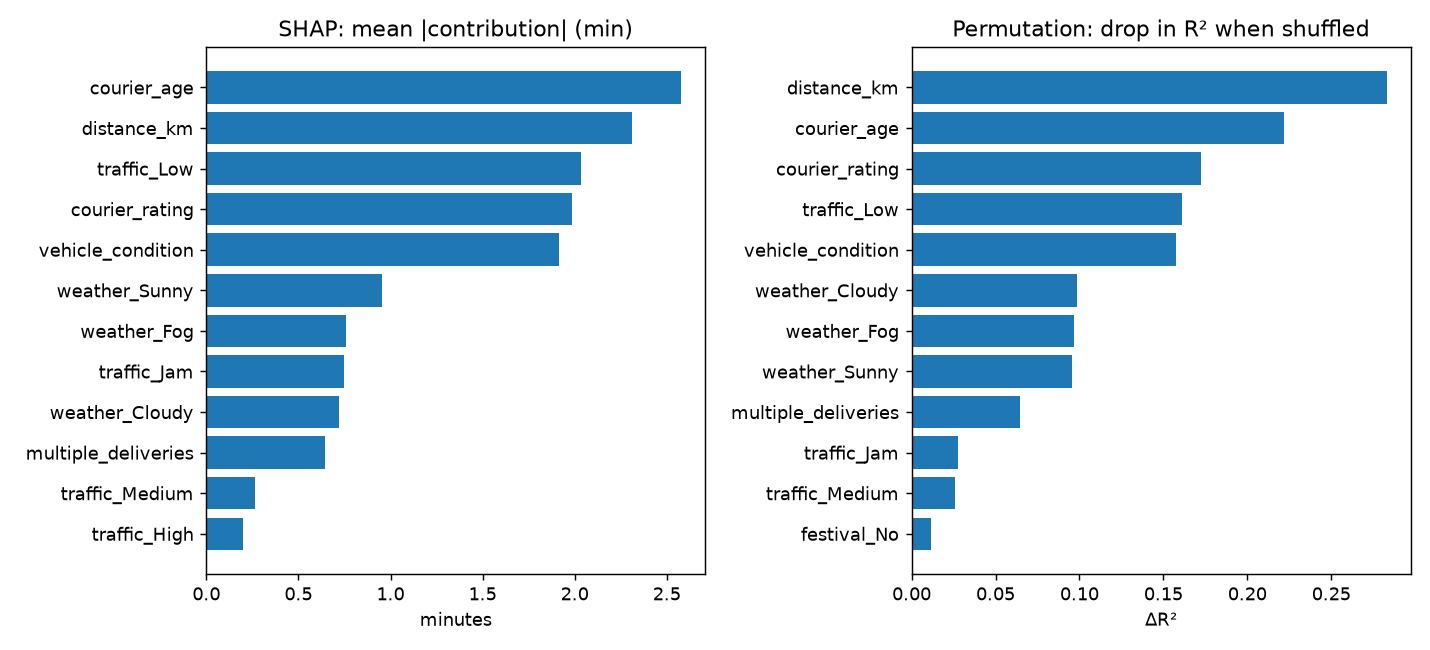

In [5]:
from IPython.display import Image, display
display(Image('../results/pred_vs_actual.png', width=420))
display(Image('../results/feature_importance.png', width=900))

## 4. Reading the importance rankings

In [6]:
imp = m['importance']
side = pd.DataFrame({'SHAP (min)': {x['feature']: x['mean_abs_shap_min'] for x in imp['shap_top']},
                     'Permutation (dR2)': {x['feature']: x['r2_drop'] for x in imp['permutation_top']}})
print(f"top-5 overlap between methods: {imp['top5_overlap']}/5")
side

top-5 overlap between methods: 5/5


,SHAP (min),Permutation (dR2)
courier_age,2.580,0.2221
distance_km,2.313,0.2830
traffic_Low,2.035,0.1610
courier_rating,1.986,0.1724
vehicle_condition,1.917,0.1577
weather_Sunny,0.956,0.0954
weather_Fog,0.757,0.0967
traffic_Jam,0.748,0.0275
weather_Cloudy,0.723,0.0986
multiple_deliveries,0.643,0.0645


Operating conditions (traffic, distance, pickup delay, stacked deliveries) and courier factors (rating, age, vehicle condition) dominate; weather and city add little once those are known. PCA compression lowered accuracy, so the full feature set is kept.